# Hyperparameter Tuning (Grid Search)

Fine-tuning the top 3 models from the baseline comparison using **GridSearchCV**.

| Model | GPU? | Notes |
|---|---|---|
| **XGBoost** (Gradient Boosting) | ✅ `device='cuda'` RTX 3050 | Superior GPU-native gradient boosting |
| **Extra Trees** | ⚡ All 12 CPU cores | sklearn has no GPU path |
| **Random Forest** | ⚡ All 12 CPU cores | sklearn has no GPU path |

> **Why XGBoost instead of sklearn GradientBoostingRegressor?**  
> sklearn's GradientBoostingRegressor has zero GPU support. XGBoost is a faster, GPU-accelerated
> gradient boosting implementation that consistently matches or beats it.

In [3]:
# ── 0. Imports ────────────────────────────────────────────────────────────────
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import time, os

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor

import xgboost as xgb

N_JOBS  = os.cpu_count()   # use all CPU cores
CV_FOLDS = 5
SEED    = 42

print(f'XGBoost : {xgb.__version__}')
print(f'CPU cores available : {N_JOBS}')

# Verify CUDA for XGBoost
try:
    _test = xgb.XGBRegressor(device='cuda', n_estimators=1)
    _test.fit([[0]], [0])
    XGB_DEVICE = 'cuda'
    print('XGBoost GPU (CUDA) : Available')
except Exception as e:
    XGB_DEVICE = 'cpu'
    print(f'XGBoost GPU : Fallback to CPU ({e})')

XGBoost : 3.2.0
CPU cores available : 12
XGBoost GPU (CUDA) : Available


In [4]:
# ── 1. Load & Split Data ──────────────────────────────────────────────────────
DATA_PATH = '../data/processed/sdss_dr17_galaxies_processed.csv'

df = pd.read_csv(DATA_PATH)

FEATURE_COLS = [
    'modelMag_u', 'modelMag_g', 'modelMag_r', 'modelMag_i', 'modelMag_z',
    'color_u_g', 'color_g_r', 'color_r_i', 'color_i_z'
]
TARGET_COL = 'specz'

X = df[FEATURE_COLS].values
y = df[TARGET_COL].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.10, random_state=SEED
)

print(f'Train : {X_train.shape[0]:,}  |  Test : {X_test.shape[0]:,}')

Train : 44,962  |  Test : 4,996


---
## Model 1 — XGBoost (GPU-accelerated Gradient Boosting)

In [5]:
# ── 2a. XGBoost Grid Search ───────────────────────────────────────────────────
xgb_param_grid = {
    'n_estimators'    : [200, 250, 300],
    'max_depth'       : [4, 6, 8],
    'learning_rate'   : [0.05, 0.1, 0.2],
    'subsample'       : [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 3],
}

# Total combinations: 3*3*3*2*2*2 = 216
total_xgb = 3*3*3*2*2*2
print(f'XGBoost grid combinations : {total_xgb} × {CV_FOLDS} folds = {total_xgb*CV_FOLDS} fits')
print(f'Running on GPU: {XGB_DEVICE.upper()}  |  This will take a few minutes ...')

xgb_base = xgb.XGBRegressor(
    device=XGB_DEVICE,
    tree_method='hist',        # 'hist' is GPU-compatible
    objective='reg:squarederror',
    random_state=SEED,
    n_jobs=1 if XGB_DEVICE == 'cuda' else N_JOBS,   # GPU handles parallelism itself
    verbosity=0
)

xgb_cv = GridSearchCV(
    estimator=xgb_base,
    param_grid=xgb_param_grid,
    cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    scoring='neg_root_mean_squared_error',
    n_jobs=1,          # XGBoost itself uses GPU; don't multi-process
    verbose=2,
    refit=True
)

t0 = time.time()
xgb_cv.fit(X_train, y_train)
xgb_time = time.time() - t0

print(f'\n✅ XGBoost grid search done in {xgb_time/60:.1f} min')
print(f'Best params : {xgb_cv.best_params_}')
print(f'Best CV RMSE: {-xgb_cv.best_score_:.5f}')

XGBoost grid combinations : 216 × 5 folds = 1080 fits
Running on GPU: CUDA  |  This will take a few minutes ...
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=4, min_child_weight=1, n_estimators=200, subsample=0.8; total time=   0.9s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=4, min_child_weight=1, n_estimators=200, subsample=0.8; total time=   0.9s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=4, min_child_weight=1, n_estimators=200, subsample=0.8; total time=   0.9s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=4, min_child_weight=1, n_estimators=200, subsample=0.8; total time=   0.9s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=4, min_child_weight=1, n_estimators=200, subsample=0.8; total time=   0.8s
[CV] END colsample_bytree=0.8, learning_rate=0.05, max_depth=4, min_child_weight=1, n_estimators=200, subsample=1.0; total time=   0.9s
[CV] END

In [6]:
# ── 2b. XGBoost Test Evaluation ───────────────────────────────────────────────
xgb_pred  = xgb_cv.best_estimator_.predict(X_test)
xgb_rmse  = np.sqrt(mean_squared_error(y_test, xgb_pred))
xgb_r2    = r2_score(y_test, xgb_pred)

print(f'XGBoost  |  Test RMSE = {xgb_rmse:.6f}  |  R² = {xgb_r2:.6f}')
print(f'Best Params: {xgb_cv.best_params_}')

XGBoost  |  Test RMSE = 0.024223  |  R² = 0.937211
Best Params: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 8, 'min_child_weight': 3, 'n_estimators': 200, 'subsample': 0.8}


---
## Model 2 — Extra Trees

In [7]:
# ── 3a. Extra Trees Grid Search ───────────────────────────────────────────────
et_param_grid = {
    'n_estimators'  : [100, 200, 400],
    'max_depth'     : [None, 15, 25],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 2, 4],
    'max_features'     : ['sqrt', 'log2', None],
}

total_et = 3*3*3*3*3
print(f'Extra Trees grid combinations : {total_et} × {CV_FOLDS} folds = {total_et*CV_FOLDS} fits')
print(f'Using all {N_JOBS} CPU cores ...')

et_base = ExtraTreesRegressor(random_state=SEED, n_jobs=N_JOBS)

et_cv = GridSearchCV(
    estimator=et_base,
    param_grid=et_param_grid,
    cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    scoring='neg_root_mean_squared_error',
    n_jobs=N_JOBS,
    verbose=2,
    refit=True
)

t0 = time.time()
et_cv.fit(X_train, y_train)
et_time = time.time() - t0

print(f'\n✅ Extra Trees grid search done in {et_time/60:.1f} min')
print(f'Best params : {et_cv.best_params_}')
print(f'Best CV RMSE: {-et_cv.best_score_:.5f}')

Extra Trees grid combinations : 243 × 5 folds = 1215 fits
Using all 12 CPU cores ...
Fitting 5 folds for each of 243 candidates, totalling 1215 fits

✅ Extra Trees grid search done in 31.7 min
Best params : {'max_depth': 25, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 400}
Best CV RMSE: 0.02471


In [8]:
# ── 3b. Extra Trees Test Evaluation ──────────────────────────────────────────
et_pred = et_cv.best_estimator_.predict(X_test)
et_rmse = np.sqrt(mean_squared_error(y_test, et_pred))
et_r2   = r2_score(y_test, et_pred)

print(f'Extra Trees  |  Test RMSE = {et_rmse:.6f}  |  R² = {et_r2:.6f}')
print(f'Best Params: {et_cv.best_params_}')

Extra Trees  |  Test RMSE = 0.024518  |  R² = 0.935672
Best Params: {'max_depth': 25, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 400}


---
## Model 3 — Random Forest

In [9]:
# ── 4a. Random Forest Grid Search ────────────────────────────────────────────
rf_param_grid = {
    'n_estimators'     : [100, 200, 400],
    'max_depth'        : [None, 15, 25],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf' : [1, 2, 4],
    'max_features'     : ['sqrt', 'log2', None],
}

total_rf = 3*3*3*3*3
print(f'Random Forest grid combinations : {total_rf} × {CV_FOLDS} folds = {total_rf*CV_FOLDS} fits')
print(f'Using all {N_JOBS} CPU cores ...')

rf_base = RandomForestRegressor(random_state=SEED, n_jobs=N_JOBS)

rf_cv = GridSearchCV(
    estimator=rf_base,
    param_grid=rf_param_grid,
    cv=KFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED),
    scoring='neg_root_mean_squared_error',
    n_jobs=N_JOBS,
    verbose=2,
    refit=True
)

t0 = time.time()
rf_cv.fit(X_train, y_train)
rf_time = time.time() - t0

print(f'\n✅ Random Forest grid search done in {rf_time/60:.1f} min')
print(f'Best params : {rf_cv.best_params_}')
print(f'Best CV RMSE: {-rf_cv.best_score_:.5f}')

Random Forest grid combinations : 243 × 5 folds = 1215 fits
Using all 12 CPU cores ...
Fitting 5 folds for each of 243 candidates, totalling 1215 fits

✅ Random Forest grid search done in 85.3 min
Best params : {'max_depth': 25, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 400}
Best CV RMSE: 0.02470


In [10]:
# ── 4b. Random Forest Test Evaluation ────────────────────────────────────────
rf_pred = rf_cv.best_estimator_.predict(X_test)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2   = r2_score(y_test, rf_pred)

print(f'Random Forest  |  Test RMSE = {rf_rmse:.6f}  |  R² = {rf_r2:.6f}')
print(f'Best Params: {rf_cv.best_params_}')

Random Forest  |  Test RMSE = 0.024456  |  R² = 0.936000
Best Params: {'max_depth': 25, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 400}


---
## Results Summary

In [11]:
# ── 5. Comparison Table ───────────────────────────────────────────────────────
# Baseline scores from notebook 02
baseline = {
    'XGBoost (Gradient Boosting)': {'baseline_rmse': 0.024869, 'baseline_r2': 0.933818},
    'Extra Trees'                : {'baseline_rmse': 0.025023, 'baseline_r2': 0.932995},
    'Random Forest'              : {'baseline_rmse': 0.025171, 'baseline_r2': 0.932201},
}

tuned = [
    {'Model': 'XGBoost (Gradient Boosting)', 'Tuned RMSE': xgb_rmse, 'Tuned R²': xgb_r2,
     'Train Time (min)': round(xgb_time/60, 1), 'Best Params': str(xgb_cv.best_params_)},
    {'Model': 'Extra Trees',                 'Tuned RMSE': et_rmse,  'Tuned R²': et_r2,
     'Train Time (min)': round(et_time/60, 1),  'Best Params': str(et_cv.best_params_)},
    {'Model': 'Random Forest',               'Tuned RMSE': rf_rmse,  'Tuned R²': rf_r2,
     'Train Time (min)': round(rf_time/60, 1),  'Best Params': str(rf_cv.best_params_)},
]

results_df = pd.DataFrame(tuned)
results_df['Baseline RMSE'] = results_df['Model'].map(lambda m: baseline[m]['baseline_rmse'])
results_df['Baseline R²']   = results_df['Model'].map(lambda m: baseline[m]['baseline_r2'])
results_df['RMSE Δ']        = (results_df['Baseline RMSE'] - results_df['Tuned RMSE']).round(6)
results_df['R² Δ']          = (results_df['Tuned R²'] - results_df['Baseline R²']).round(6)

display_cols = ['Model', 'Baseline RMSE', 'Tuned RMSE', 'RMSE Δ', 'Baseline R²', 'Tuned R²', 'R² Δ', 'Train Time (min)']
print('=== Tuning Results vs Baseline ===')
results_df[display_cols].style \
    .format({'Baseline RMSE': '{:.6f}', 'Tuned RMSE': '{:.6f}', 'RMSE Δ': '{:+.6f}',
             'Baseline R²': '{:.6f}', 'Tuned R²': '{:.6f}', 'R² Δ': '{:+.6f}'}) \
    .background_gradient(subset=['RMSE Δ'], cmap='RdYlGn') \
    .background_gradient(subset=['R² Δ'],   cmap='RdYlGn')

=== Tuning Results vs Baseline ===


,Model,Baseline RMSE,Tuned RMSE,RMSE Δ,Baseline R²,Tuned R²,R² Δ,Train Time (min)
0,XGBoost (Gradient Boosting),0.024869,0.024223,+0.000646,0.933818,0.937211,+0.003393,36.100000
1,Extra Trees,0.025023,0.024518,+0.000505,0.932995,0.935672,+0.002677,31.700000
2,Random Forest,0.025171,0.024456,+0.000715,0.932201,0.936000,+0.003799,85.300000


In [13]:
# ── 6. Best Params Summary ────────────────────────────────────────────────────
print('\n' + '='*65)
print('  BEST HYPERPARAMETERS FOUND')
print('='*65)
print(f"\n🟢 XGBoost")
for k, v in xgb_cv.best_params_.items():
    print(f"   {k:25s} = {v}")
print(f"\n🔵 Extra Trees")
for k, v in et_cv.best_params_.items():
    print(f"   {k:25s} = {v}")
print(f"\n🟠 Random Forest")
for k, v in rf_cv.best_params_.items():
    print(f"   {k:25s} = {v}")


  BEST HYPERPARAMETERS FOUND

🟢 XGBoost
   colsample_bytree          = 0.8
   learning_rate             = 0.05
   max_depth                 = 8
   min_child_weight          = 3
   n_estimators              = 200
   subsample                 = 0.8

🔵 Extra Trees
   max_depth                 = 25
   max_features              = None
   min_samples_leaf          = 1
   min_samples_split         = 10
   n_estimators              = 400

🟠 Random Forest
   max_depth                 = 25
   max_features              = sqrt
   min_samples_leaf          = 1
   min_samples_split         = 5
   n_estimators              = 400


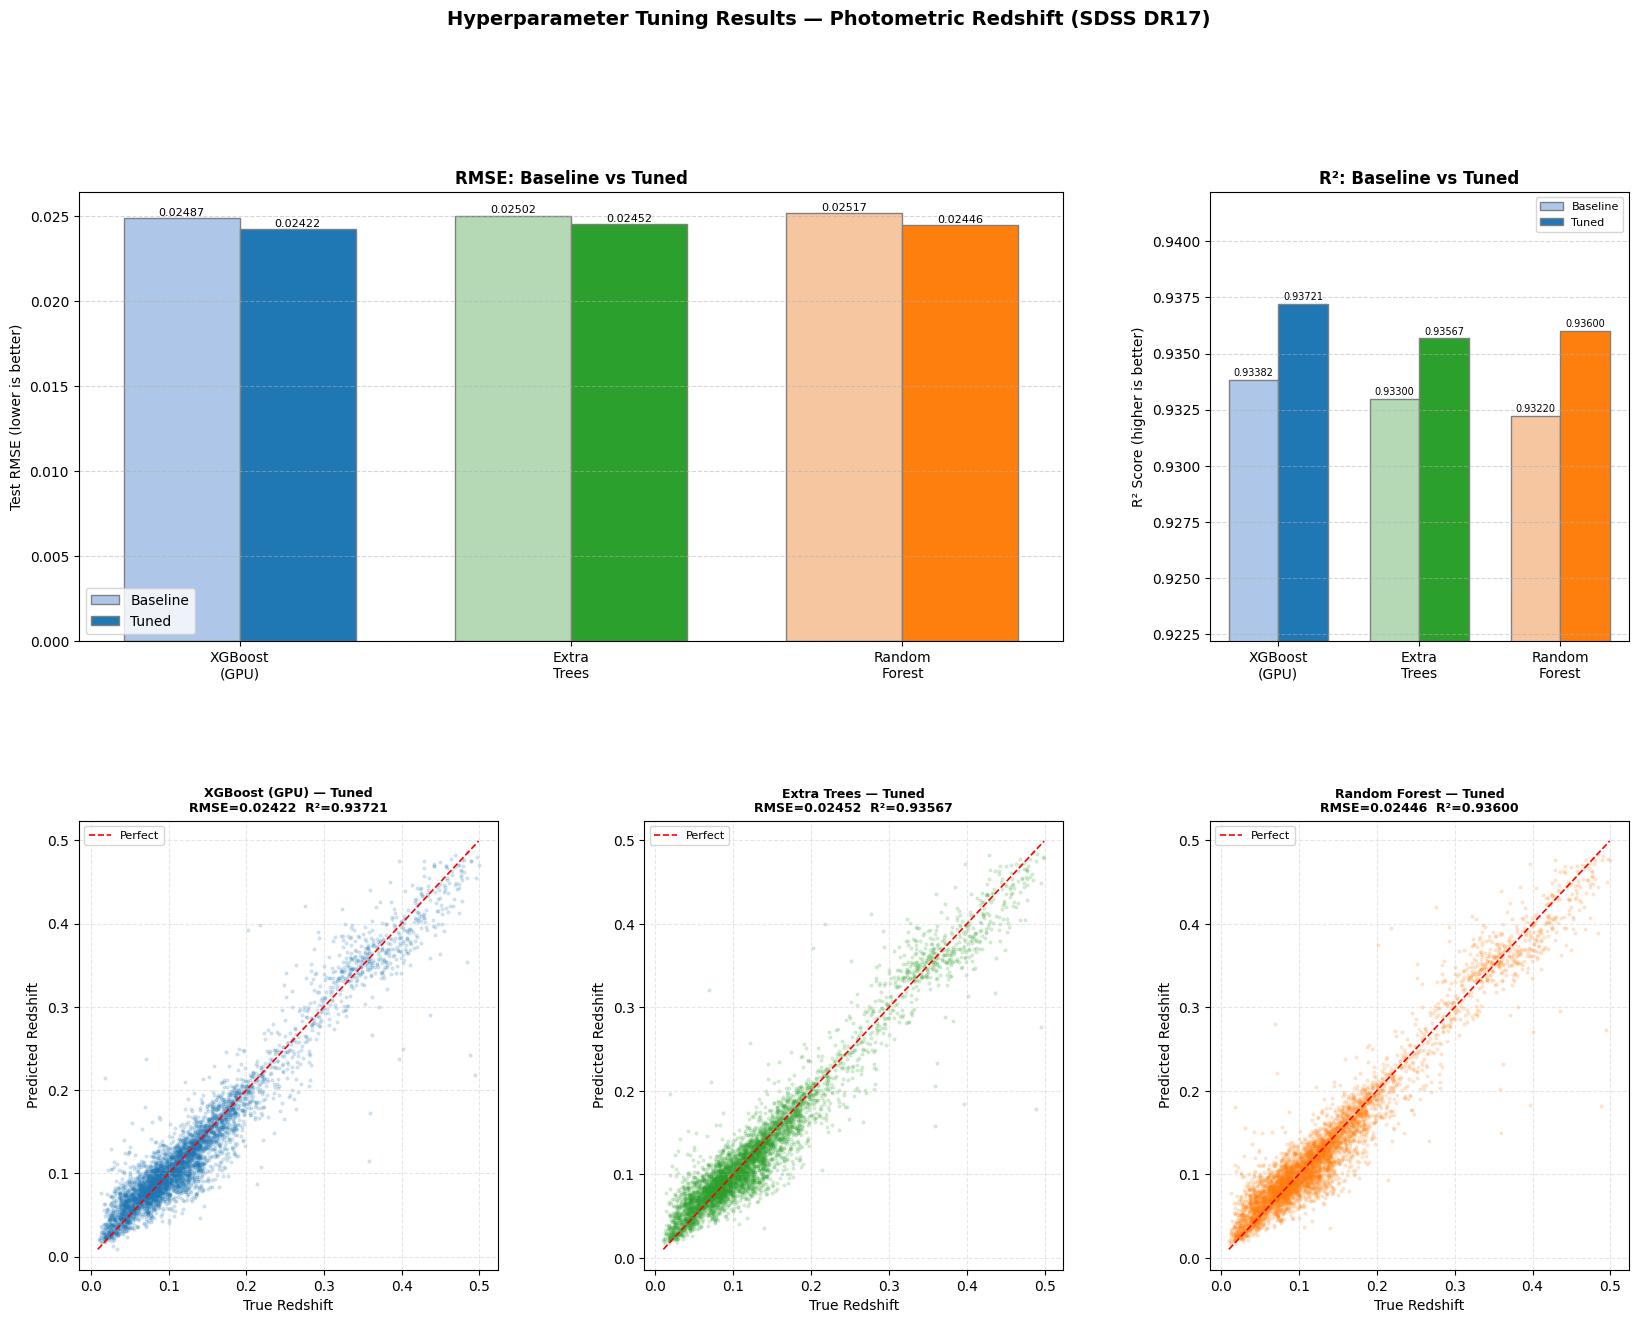

Figure saved → results/figures/tuning_comparison.png


In [16]:
# ── 7. Visualisation ──────────────────────────────────────────────────────────
fig = plt.figure(figsize=(20, 14))
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.35)

model_names  = ['XGBoost\n(GPU)', 'Extra\nTrees', 'Random\nForest']
base_rmses   = [0.024869, 0.025023, 0.025171]
tuned_rmses  = [xgb_rmse, et_rmse, rf_rmse]
base_r2s     = [0.933818, 0.932995, 0.932201]
tuned_r2s    = [xgb_r2, et_r2, rf_r2]
preds        = [xgb_pred, et_pred, rf_pred]
colors_base  = ['#aec6e8', '#b5d9b5', '#f5c6a0']
colors_tuned = ['#1f77b4', '#2ca02c', '#ff7f0e']

# — Row 1: RMSE comparison + R² comparison
ax_rmse = fig.add_subplot(gs[0, 0:2])
x = np.arange(len(model_names))
w = 0.35
bars1 = ax_rmse.bar(x - w/2, base_rmses,  w, label='Baseline', color=colors_base,  edgecolor='grey')
bars2 = ax_rmse.bar(x + w/2, tuned_rmses, w, label='Tuned',    color=colors_tuned, edgecolor='grey')
for bar in bars1 + bars2:
    ax_rmse.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.00005,
                 f'{bar.get_height():.5f}', ha='center', va='bottom', fontsize=8)
ax_rmse.set_xticks(x); ax_rmse.set_xticklabels(model_names, fontsize=10)
ax_rmse.set_ylabel('Test RMSE (lower is better)')
ax_rmse.set_title('RMSE: Baseline vs Tuned', fontweight='bold')
ax_rmse.legend(); ax_rmse.grid(axis='y', linestyle='--', alpha=0.5)

ax_r2 = fig.add_subplot(gs[0, 2])
bars3 = ax_r2.bar(x - w/2, base_r2s,  w, label='Baseline', color=colors_base,  edgecolor='grey')
bars4 = ax_r2.bar(x + w/2, tuned_r2s, w, label='Tuned',    color=colors_tuned, edgecolor='grey')
for bar in bars3 + bars4:
    ax_r2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.0001,
               f'{bar.get_height():.5f}', ha='center', va='bottom', fontsize=7)
ax_r2.set_xticks(x); ax_r2.set_xticklabels(model_names, fontsize=10)
ax_r2.set_ylabel('R² Score (higher is better)')
ax_r2.set_title('R²: Baseline vs Tuned', fontweight='bold')
ax_r2.legend(fontsize=8); ax_r2.grid(axis='y', linestyle='--', alpha=0.5)
ax_r2.set_ylim([min(base_r2s)-0.01, max(tuned_r2s)+0.005])

# — Row 2: Predicted vs Actual for each tuned model
titles = ['XGBoost (GPU) — Tuned', 'Extra Trees — Tuned', 'Random Forest — Tuned']
for i, (pred, color, title) in enumerate(zip(preds, colors_tuned, titles)):
    ax = fig.add_subplot(gs[1, i])
    ax.scatter(y_test, pred, alpha=0.15, s=4, color=color)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, 'r--', lw=1.2, label='Perfect')
    rmse_i = tuned_rmses[i]; r2_i = tuned_r2s[i]
    ax.set_title(f'{title}\nRMSE={rmse_i:.5f}  R²={r2_i:.5f}', fontsize=9, fontweight='bold')
    ax.set_xlabel('True Redshift'); ax.set_ylabel('Predicted Redshift')
    ax.legend(fontsize=8); ax.grid(True, linestyle='--', alpha=0.3)

fig.suptitle('Hyperparameter Tuning Results — Photometric Redshift (SDSS DR17)',
             fontsize=14, fontweight='bold', y=1.01)

plt.savefig('../results/figures/tuning_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved → results/figures/tuning_comparison.png')

In [17]:
# ── 8. Save Results ───────────────────────────────────────────────────────────
out_path = '../results/metrics/tuning_results.csv'
results_df.to_csv(out_path, index=False)
print(f'Results saved → {out_path}')

# Final summary
best_model_idx = results_df['Tuned RMSE'].idxmin()
best = results_df.loc[best_model_idx]

print('\n' + '='*60)
print('  FINAL TUNING SUMMARY')
print('='*60)
print(results_df[['Model','Baseline RMSE','Tuned RMSE','RMSE Δ','Baseline R²','Tuned R²','R² Δ']].to_string(index=False))
print('='*60)
print(f"\n🏆  Best tuned model → {best['Model']}")
print(f"    RMSE : {best['Tuned RMSE']:.6f}  (Δ {best['Baseline RMSE']-best['Tuned RMSE']:+.6f} vs baseline)")
print(f"    R²   : {best['Tuned R²']:.6f}  (Δ {best['Tuned R²']-best['Baseline R²']:+.6f} vs baseline)")

Results saved → ../results/metrics/tuning_results.csv

  FINAL TUNING SUMMARY
                      Model  Baseline RMSE  Tuned RMSE   RMSE Δ  Baseline R²  Tuned R²     R² Δ
XGBoost (Gradient Boosting)       0.024869    0.024223 0.000646     0.933818  0.937211 0.003393
                Extra Trees       0.025023    0.024518 0.000505     0.932995  0.935672 0.002677
              Random Forest       0.025171    0.024456 0.000715     0.932201  0.936000 0.003799

🏆  Best tuned model → XGBoost (Gradient Boosting)
    RMSE : 0.024223  (Δ +0.000646 vs baseline)
    R²   : 0.937211  (Δ +0.003393 vs baseline)
